# X1C — O pool não rotulado (teto 8000 + stride 3) mudou os resultados do X1?

Todos os sweeps da família X1 (`x1`, `x1-binario`, `x1-frames-per-video*`) montaram o pool não
rotulado com **teto de 8000 frames e stride 3**. O X1B usou o pool **denso**: sem teto, stride 1.
A pergunta deste notebook é operacional: **os resultados já gravados precisam ser refeitos com o
pool denso?**

O que o teto e o stride fazem, com os números deste fold (seção 1):

- stride 3 deixa ~10,7k frames elegíveis; stride 1, ~32k. O teto de 8000 corta **os dois** casos,
  então trocar só o stride não muda o tamanho do pool — muda de onde os 8000 são sorteados.
- Com 8000 passos × 4 slots não rotulados = 32.000 sorteios, cada frame do pool de 8000 é visto
  ~4× em média; no pool denso, ~1×.

## Desenho

| Eixo | Valores | Por quê |
|---|---|---|
| `pool` | `old` (8000 / stride 3) · `new` (sem teto / stride 1) | a variável em teste |
| `frames_per_video` | 1 · 5 | os extremos: 1 é onde a política `same_video` mais aperta a cobertura; 5 revela todos os 690 rótulos (o regime "publicável") |
| `method` | supervised · fixmatch · meanteacher | DiffRect fica de fora nesta rodada: custa 2× por célula |
| `seed` | 42 · 43 · 44 | **necessário**: re-runs idênticos do X1 já divergiram até ~0,10 de Dice com a mesma seed (ver seção 3). Sem réplicas não há como separar efeito do pool de ruído de treino |

Grade: `configs/sweep/x1-pool-ablation-s{42,43,44}.yaml` (plano `X1PoolAblationSweep` em
`src/sweeps/x1.py`), uma família por seed para as três rodarem em paralelo. O braço `old` reproduz a
config dos runs gravados em `logs/x1-frames-per-video/` (conferido chave a chave contra o
`hparams.yaml`); o braço `new` difere **só** em `unlabeled_pool_size` e `unlabeled_pool_frame_stride`.

## Regra de decisão (fixada antes de ver os resultados)

Métrica primária: Dice médio do run no teste (média sobre frames e sobre C2, C4). Para cada
`(frames_per_video, method)`, com `n` seeds pareadas:

1. **Deslocamento do método**: Δ = média(new − old). Relevante se `|Δ| > max(2·EP, LIMIAR)`.
2. **Deslocamento da margem SSL**: Δmargem = média[(SSL − sup)_new − (SSL − sup)_old], pareado por
   seed. É o número que o X1 reporta. Relevante se `|Δmargem| > max(2·EP, LIMIAR)`.
3. **Inversão de conclusão**: a margem média muda de sinal entre os pools, com as duas margens maiores
   que o próprio erro-padrão.

`LIMIAR = 0,02` de Dice (editável abaixo). Veredito:

- **RE-RODAR** se qualquer critério disparar em qualquer célula;
- **MANTER** se nenhum disparar **e** a resolução for suficiente (2·EP ≤ 0,05 em todas as células);
- **INCONCLUSIVO** caso contrário — o ruído entre seeds é maior do que o efeito que dá para detectar
  com 3 seeds, e a decisão exige mais réplicas.

Métricas de superfície (HD95/ASSD) entram como diagnóstico, não como critério, e sempre com a taxa de
estrutura não detectada ao lado (o valor de penalidade é a diagonal da imagem, 362,04).

In [1]:
import os
import sys
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.data.vfss_frame_dataset import apply_label_regime_by_count, build_unlabeled_frame_pool
from src.sweep import Sweep

pd.set_option("display.precision", 4)
pd.set_option("display.width", 160)

SEEDS = [42, 43, 44]
LIMIAR = 0.02            # Dice: abaixo disto uma diferenca nao muda leitura nenhuma do X1
RESOLUCAO_MAXIMA = 0.05  # 2*EP acima disto: a celula nao resolve efeitos relevantes
PENALIDADE = 362.0       # _max_distance((256, 256)) = 362.04: estrutura nao detectada
SSL_METHODS = ["fixmatch", "meanteacher"]

SWEEPS = {s: Sweep(f"configs/sweep/x1-pool-ablation-s{s}.yaml") for s in SEEDS}
PLAN = SWEEPS[SEEDS[0]].plan
CFG = PLAN.config

/home/caioseda/miniconda3/envs/vfss/lib/python3.12/site-packages/timm/models/layers/__init__.py:49: FutureWarning: Importing from timm.models.layers is deprecated, please import via timm.layers
  warnings.warn(f"Importing from {__name__} is deprecated, please import via timm.layers", FutureWarning)


## 1. O que muda no pool (sem treino)

Para cada configuração: tamanho, cobertura por vídeo, quantos pares de frames do mesmo vídeo ficam a
menos de 3 frames de distância (quase-duplicatas), e — dado o regime de rótulos e a política
`same_video` — quantas vezes cada frame deve ser sorteado e quantos frames **distintos** o treino
chega a ver.

Sob `same_video`, cada slot não rotulado é ancorado num frame rotulado do batch e sorteia uniforme
entre os frames do pool do vídeo da âncora. Então o vídeo `v` recebe
`D · L_v / L` sorteios (D = 32.000, `L_v` rótulos revelados de `v`), divididos entre os `n_v` frames
dele no pool.

In [2]:
df = PLAN._dataframe()
draws = int(CFG.training.max_steps) * (int(CFG.training.batch_size) - int(CFG.training.labeled_batch_size))

pools = {}
for name, spec in CFG.pools.items():
    pools[name] = build_unlabeled_frame_pool(
        CFG.data.dataset_path, df, splits=tuple(CFG.data.unlabeled_pool_splits),
        pool_size=spec.get("unlabeled_pool_size"),
        frame_stride=int(spec.unlabeled_pool_frame_stride),
        seed=int(CFG.data.unlabeled_pool_seed),
    )

rows = []
for fpv in CFG.axes.frames_per_video:
    regime = apply_label_regime_by_count(df, group_column=CFG.data.label_group_column,
                                         frames_per_group=int(fpv), seed=int(CFG.data.label_seed))
    labeled = regime[(regime.split == "train") & regime.is_labeled].groupby("video_id").size()
    for name, pool in pools.items():
        per_video = pool.groupby("video_id").size()
        gaps = (pool.sort_values(["video_id", "frame_id"])
                    .groupby("video_id").frame_id.diff().dropna())
        draws_v = draws * labeled.reindex(per_video.index).fillna(0) / labeled.sum()
        visits = draws_v / per_video                         # sorteios esperados por frame, por video
        seen = per_video * (1 - (1 - 1 / per_video) ** draws_v)  # frames distintos vistos, esperado
        visits_per_frame = np.repeat(visits.to_numpy(), per_video.to_numpy())
        rows.append({
            "frames/vídeo": fpv, "pool": name,
            "frames no pool": len(pool), "vídeos": per_video.size,
            "frames/vídeo (mediana)": per_video.median(),
            "% pares com gap < 3": 100 * (gaps < 3).mean(),
            "visitas/frame (média)": visits_per_frame.mean(),
            "visitas/frame (p95)": np.percentile(visits_per_frame, 95),
            "frames distintos vistos": seen.sum(),
            "% do pool visto": 100 * seen.sum() / len(pool),
        })
pool_stats = pd.DataFrame(rows).set_index(["frames/vídeo", "pool"])
pool_stats.round(2)

frames no pool  vídeos  frames/vídeo (mediana)  % pares com gap < 3  visitas/frame (média)  visitas/frame (p95)  frames distintos vistos  \
frames/vídeo pool                                                                                                                                             
1            old             8000     165                    54.0                 0.00                    4.0                 6.69                  7759.57   
             new            31953     165                   211.0                99.76                    1.0                 1.64                 19447.38   
5            old             8000     165                    54.0                 0.00                    4.0                 6.40                  7743.03   
             new            31953     165                   211.0                99.76                    1.0                 1.55                 19414.56   

                   % do pool visto  
frames/vídeo pool                   
1            old             96.99  
             new             60.86  
5            old             96.79  
             new             60.76

## 2. Evidência gratuita: X1 (100%) × X1B (`same_video`)

A célula `lf100` do X1 e a célula `same_video` do X1B têm a mesma config exceto o pool (8000/3 contra
denso), mesma seed. E `lf100` do X1 e `fpv05` do X1-frames-por-vídeo revelam os **mesmos 690
rótulos** com o **mesmo pool**: são, na prática, dois treinos da mesma config. Isso dá, sem treinar
nada, um "efeito do pool" e um "ruído de re-run" na mesma escala.

Ressalvas: uma seed só; o X1B rodou em 2026-09-10 e o X1 em 2026-09-14/15, sem sha de git gravado
(deriva de código não é separável); a CSV do X1B está na convenção antiga de ASSD/HD95 (NaN no lugar
da penalidade), então aqui só Dice/IoU.

In [3]:
def run_level(per_sample: pd.DataFrame, keys) -> pd.DataFrame:
    '''Uma linha por run: Dice/IoU medios por classe e no geral, HD95 e taxa de nao-deteccao.'''
    frame = per_sample.copy()
    frame["undetected"] = frame.hd95.isna() | (frame.hd95 >= PENALIDADE)
    by_class = frame.pivot_table(index=keys, columns="class", values="dice", aggfunc="mean")
    by_class.columns = [f"dice_{c}" for c in by_class.columns]
    overall = frame.groupby(keys).agg(dice=("dice", "mean"), iou=("iou", "mean"),
                                      hd95=("hd95", "mean"), undetected=("undetected", "mean"),
                                      n=("dice", "size"))
    return overall.join(by_class).reset_index()


x1 = pd.read_csv("logs/x1/results_per_sample.csv")
x1b = pd.read_csv("logs/x1b/results_per_sample.csv")
fpv = pd.read_csv("logs/x1-frames-per-video/results_per_sample.csv")

free = pd.concat([
    run_level(x1[x1.label_fraction == 1.0].assign(fonte="X1 lf100 (pool old)"), ["fonte", "method"]),
    run_level(fpv[fpv.frames_per_video == 5].assign(fonte="X1-fpv fpv05 (pool old, re-run)"), ["fonte", "method"]),
    run_level(x1b[x1b.policy == "same_video"].assign(fonte="X1B same_video (pool new)"), ["fonte", "method"]),
])
free = free[free.method.isin(["supervised", "fixmatch", "meanteacher"])]
free_wide = free.pivot(index="method", columns="fonte", values="dice")
free_wide["re-run: fpv05 − lf100"] = free_wide["X1-fpv fpv05 (pool old, re-run)"] - free_wide["X1 lf100 (pool old)"]
free_wide["pool: X1B − lf100"] = free_wide["X1B same_video (pool new)"] - free_wide["X1 lf100 (pool old)"]
free_wide.round(4)

fonte,X1 lf100 (pool old),"X1-fpv fpv05 (pool old, re-run)",X1B same_video (pool new),re-run: fpv05 − lf100,pool: X1B − lf100
method,,,,,
fixmatch,0.8278,0.7973,0.8307,-0.0304,0.0030
meanteacher,0.8504,0.8354,0.8596,-0.0150,0.0092
supervised,0.8152,0.8074,0.8577,-0.0078,0.0425


In [4]:
free_margin = free_wide.drop(columns=[c for c in free_wide.columns if ":" in c])
free_margin = (free_margin - free_margin.loc["supervised"]).drop(index="supervised")
print("Margem SSL − supervisionado (Dice), por fonte:")
free_margin.round(4)

Margem SSL − supervisionado (Dice), por fonte:


fonte,X1 lf100 (pool old),"X1-fpv fpv05 (pool old, re-run)",X1B same_video (pool new)
method,,,
fixmatch,0.0126,-0.0101,-0.0269
meanteacher,0.0352,0.0280,0.0019


## 3. A ablação

Estado da grade (as três famílias rodam em paralelo em sessões tmux `pool-abl-s42/43/44`):

In [5]:
status = pd.concat([sw.plan_summary() for sw in SWEEPS.values()])
print(status.status.value_counts().to_string())
status.pivot_table(index=["frames_per_video", "method"], columns=["pool", "seed"],
                   values="status", aggfunc="first")

status
done (na CSV)    36


pool                                    new                                          old                              
seed                                     42             43             44             42             43             44
frames_per_video method                                                                                               
1                fixmatch     done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)
                 meanteacher  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)
                 supervised   done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)
5                fixmatch     done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)
                 meanteacher  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)
                 supervised   done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)  done (na CSV)

In [6]:
frames = [sw.load_results() for sw in SWEEPS.values()]
ablation = pd.concat([f for f in frames if len(f)], ignore_index=True) if any(len(f) for f in frames) else pd.DataFrame()
keys = ["frames_per_video", "method", "pool", "seed"]
runs = run_level(ablation, keys) if len(ablation) else pd.DataFrame(columns=keys + ["dice"])

# Os runs ja gravados (pool old, seed 42) entram como referencia de re-run, nao na estatistica.
recorded = run_level(fpv[fpv.frames_per_video.isin(CFG.axes.frames_per_video)
                         & fpv.method.isin(CFG.axes.method)].assign(pool="old (gravado)"), keys)

print(f"{len(runs)} runs da ablacao concluidos de {len(status)}")
pd.concat([runs, recorded]).sort_values(keys).round(4)

36 runs da ablacao concluidos de 36


,frames_per_video,method,pool,seed,dice,iou,hd95,undetected,n,dice_C2,dice_C4
0,1,fixmatch,new,42,0.7556,0.6551,10.0256,0.0058,344,0.8184,0.6928
1,1,fixmatch,new,43,0.7741,0.6793,12.9700,0.0145,344,0.8264,0.7217
2,1,fixmatch,new,44,0.7574,0.6666,18.8399,0.0320,344,0.8009,0.7139
3,1,fixmatch,old,42,0.6907,0.5841,16.7270,0.0262,344,0.7672,0.6141
4,1,fixmatch,old,43,0.7825,0.6836,11.5362,0.0000,344,0.8546,0.7104
5,1,fixmatch,old,44,0.7747,0.6777,8.7004,0.0000,344,0.8060,0.7433
0,1,fixmatch,old (gravado),42,0.7499,0.6600,25.5999,0.0494,344,0.7630,0.7368
6,1,meanteacher,new,42,0.7296,0.6211,19.1590,0.0320,344,0.7849,0.6744
7,1,meanteacher,new,43,0.7798,0.6898,10.7530,0.0058,344,0.8313,0.7284
8,1,meanteacher,new,44,0.7172,0.6162,14.8074,0.0058,344,0.7476,0.6868


### 3.1 Ruído de re-run: o mesmo braço `old`, seed 42, treinado de novo

Se esta diferença já for da ordem do efeito procurado, uma comparação de seed única não serve — é o
motivo das três seeds.

In [7]:
rerun = recorded.merge(runs[(runs.pool == "old") & (runs.seed == 42)],
                       on=["frames_per_video", "method", "seed"], suffixes=("_gravado", "_agora"))
rerun["Δ dice (agora − gravado)"] = rerun.dice_agora - rerun.dice_gravado
rerun[["frames_per_video", "method", "dice_gravado", "dice_agora", "Δ dice (agora − gravado)"]].round(4)

,frames_per_video,method,dice_gravado,dice_agora,Δ dice (agora − gravado)
0,1,fixmatch,0.7499,0.6907,-0.0593
1,1,meanteacher,0.7209,0.7476,0.0267
2,1,supervised,0.7366,0.7379,0.0013
3,5,fixmatch,0.7973,0.8135,0.0162
4,5,meanteacher,0.8354,0.8151,-0.0203
5,5,supervised,0.8074,0.8436,0.0361


### 3.2 Efeito do pool por método e margem SSL − supervisionado

In [8]:
def paired_summary(wide: pd.DataFrame, a: str, b: str) -> pd.Series:
    d = (wide[b] - wide[a]).dropna()
    n = len(d)
    se = d.std(ddof=1) / np.sqrt(n) if n > 1 else np.nan
    return pd.Series({"n": n, "média old": wide[a].mean(), "dp old": wide[a].std(ddof=1),
                      "média new": wide[b].mean(), "dp new": wide[b].std(ddof=1),
                      "Δ (new − old)": d.mean(), "EP Δ": se})


if len(runs):
    dice = runs.pivot_table(index=["frames_per_video", "method", "seed"], columns="pool", values="dice")
    effect = dice.groupby(level=["frames_per_video", "method"]).apply(paired_summary, "old", "new")

    margin = dice.copy()
    sup = margin.xs("supervised", level="method")
    margin = margin.drop(index="supervised", level="method")
    margin = margin - sup.reindex(margin.index.droplevel("method")).to_numpy()
    margin_effect = margin.groupby(level=["frames_per_video", "method"]).apply(paired_summary, "old", "new")
    margin_effect = margin_effect.rename(columns=lambda c: c.replace("média", "margem").replace("dp", "dp margem"))
    display(effect.round(4))
    print("Margem SSL − supervisionado (pareada por seed):")
    display(margin_effect.round(4))

n  média old  dp old  média new  dp new  Δ (new − old)    EP Δ
frames_per_video method                                                                       
1                fixmatch     3.0     0.7493  0.0509     0.7623  0.0102         0.0131  0.0260
                 meanteacher  3.0     0.7568  0.0208     0.7422  0.0332        -0.0146  0.0292
                 supervised   3.0     0.7301  0.0160     0.7430  0.0366         0.0129  0.0278
5                fixmatch     3.0     0.7970  0.0320     0.7998  0.0148         0.0029  0.0260
                 meanteacher  3.0     0.8167  0.0470     0.8036  0.0210        -0.0131  0.0179
                 supervised   3.0     0.8050  0.0438     0.7893  0.0254        -0.0157  0.0130

Margem SSL − supervisionado (pareada por seed):


n  margem old  dp margem old  margem new  dp margem new  Δ (new − old)    EP Δ
frames_per_video method                                                                                       
1                fixmatch     3.0      0.0192         0.0604      0.0194         0.0330         0.0002  0.0320
                 meanteacher  3.0      0.0267         0.0155     -0.0007         0.0273        -0.0274  0.0075
5                fixmatch     3.0     -0.0080         0.0190      0.0105         0.0387         0.0186  0.0178
                 meanteacher  3.0      0.0117         0.0395      0.0143         0.0045         0.0026  0.0235

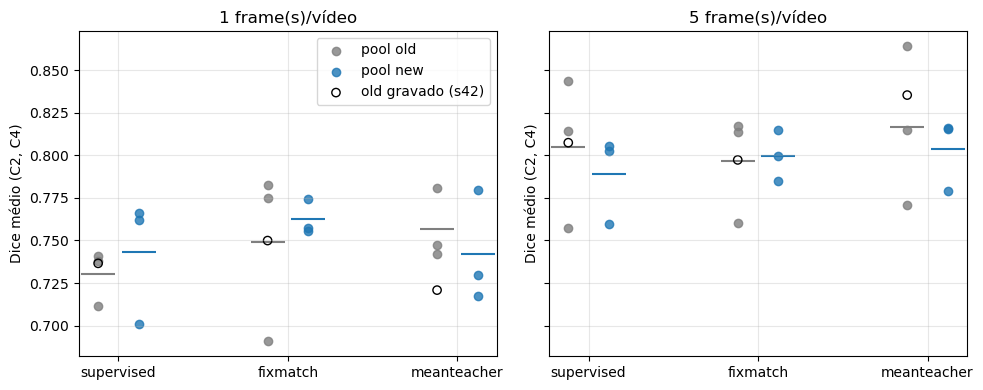

In [9]:
if len(runs):
    budgets = list(CFG.axes.frames_per_video)
    fig, axes = plt.subplots(1, len(budgets), figsize=(5 * len(budgets), 4), sharey=True)
    methods = list(CFG.axes.method)
    for ax, budget in zip(np.atleast_1d(axes), budgets):
        sub = runs[runs.frames_per_video == budget]
        for offset, (pool, color) in zip((-0.12, 0.12), (("old", "tab:gray"), ("new", "tab:blue"))):
            part = sub[sub.pool == pool]
            x = part.method.map({m: i for i, m in enumerate(methods)}) + offset
            ax.scatter(x, part.dice, color=color, label=f"pool {pool}", alpha=0.8)
            means = part.groupby("method").dice.mean().reindex(methods)
            ax.scatter(np.arange(len(methods)) + offset, means, color=color, marker="_", s=600)
        rec = recorded[recorded.frames_per_video == budget]
        ax.scatter(rec.method.map({m: i for i, m in enumerate(methods)}) - 0.12, rec.dice,
                   facecolors="none", edgecolors="black", label="old gravado (s42)")
        ax.set_xticks(range(len(methods)), methods)
        ax.set_title(f"{budget} frame(s)/vídeo")
        ax.set_ylabel("Dice médio (C2, C4)")
        ax.grid(alpha=0.3)
    np.atleast_1d(axes)[0].legend()
    plt.tight_layout()
    plt.show()

### 3.3 Diagnóstico de superfície

HD95 médio com a penalidade incluída, ao lado da fração de pares (frame, classe) em que a estrutura
não foi detectada. Uma mudança de HD95 acompanhada de mudança na não-detecção é efeito da penalidade,
não de localização.

In [10]:
if len(runs):
    display(runs.groupby(["frames_per_video", "method", "pool"])[["hd95", "undetected"]]
                .agg(["mean", "std"]).round(3))

hd95         undetected       
                                     mean     std       mean    std
frames_per_video method      pool                                  
1                fixmatch    new   13.945   4.487      0.017  0.013
                             old   12.321   4.070      0.009  0.015
                 meanteacher new   14.906   4.204      0.015  0.015
                             old   11.629   3.848      0.010  0.012
                 supervised  new   13.536   0.490      0.008  0.004
                             old   25.118  10.481      0.044  0.034
5                fixmatch    new   14.250   9.262      0.024  0.029
                             old   13.533   2.326      0.018  0.009
                 meanteacher new   11.688   5.345      0.016  0.017
                             old   10.068   3.262      0.014  0.003
                 supervised  new   20.351   2.369      0.040  0.008
                             old   18.464  12.278      0.039  0.034

## 4. Veredito

In [11]:
def verdict(effect: pd.DataFrame, margin_effect: pd.DataFrame, expected_pairs: int):
    findings, low_resolution = [], []
    for (budget, method), row in effect.iterrows():
        bar = max(2 * row["EP Δ"], LIMIAR)
        if abs(row["Δ (new − old)"]) > bar:
            findings.append(f"[metodo] {method} @ {budget} f/v: Δ={row['Δ (new − old)']:+.4f} > {bar:.4f}")
        if 2 * row["EP Δ"] > RESOLUCAO_MAXIMA:
            low_resolution.append(f"{method} @ {budget} f/v: 2·EP={2 * row['EP Δ']:.4f}")
    for (budget, method), row in margin_effect.iterrows():
        bar = max(2 * row["EP Δ"], LIMIAR)
        if abs(row["Δ (new − old)"]) > bar:
            findings.append(f"[margem] {method} @ {budget} f/v: Δmargem={row['Δ (new − old)']:+.4f} > {bar:.4f}")
        old, new = row["margem old"], row["margem new"]
        if (np.sign(old) != np.sign(new) and abs(old) > row["dp margem old"] / np.sqrt(row["n"])
                and abs(new) > row["dp margem new"] / np.sqrt(row["n"])):
            findings.append(f"[inversao] {method} @ {budget} f/v: margem {old:+.4f} (old) -> {new:+.4f} (new)")
        if 2 * row["EP Δ"] > RESOLUCAO_MAXIMA:
            low_resolution.append(f"margem {method} @ {budget} f/v: 2·EP={2 * row['EP Δ']:.4f}")

    complete = (effect["n"] >= expected_pairs).all()
    if findings:
        label = "RE-RODAR"
    elif low_resolution:
        label = "INCONCLUSIVO"
    else:
        label = "MANTER"
    return label, findings, low_resolution, complete


if len(runs):
    label, findings, low_resolution, complete = verdict(effect, margin_effect, len(SEEDS))
    if not complete:
        print("ATENCAO: grade incompleta -- veredito PARCIAL, nao use para decidir.\n")
    print(f"VEREDITO: {label}\n")
    for line in findings:
        print("  ", line)
    if low_resolution:
        print("\nCelulas sem resolucao suficiente (2·EP > %.2f):" % RESOLUCAO_MAXIMA)
        for line in low_resolution:
            print("  ", line)

VEREDITO: RE-RODAR

   [margem] meanteacher @ 1 f/v: Δmargem=-0.0274 > 0.0200

Celulas sem resolucao suficiente (2·EP > 0.05):
   fixmatch @ 1 f/v: 2·EP=0.0521
   meanteacher @ 1 f/v: 2·EP=0.0585
   supervised @ 1 f/v: 2·EP=0.0557
   fixmatch @ 5 f/v: 2·EP=0.0521
   margem fixmatch @ 1 f/v: 2·EP=0.0641


### Como ler o veredito para os outros notebooks

- `x1-binario` nunca rodou (`logs/x1-binario/` não existe): rode direto com o pool que este
  notebook indicar, não há o que comparar.
- `x1-frames-per-video-binario-all` e `-multiclass-all` usam exatamente o mesmo mecanismo de pool
  (a construção do pool não depende do alvo); o que muda é a loss sobre ele. **MANTER** aqui é
  evidência razoável para eles; **RE-RODAR** aqui vale para todos.
- DiffRect não está na ablação. Se o veredito for MANTER, vale uma checagem pontual dele (1 orçamento,
  3 seeds, 2 pools = 6 runs de ~50 min) antes de estender a conclusão a ele.